# Baseline 2 — 7-day average profile

**Idea:** the forecast for each 15-minute block of day D+1 is the average power at that same block over the last 7 days (D-6 … D).

Averaging smooths out a single cloudy day, which persistence copies straight into tomorrow. No training and nothing to tune.

Input: `Data/Clean/Winter_Clean.csv`. Settings, split and metrics are identical to the persistence notebook so the two are directly comparable.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Settings

In [2]:
# Works whether the notebook is opened from src/ or from the project folder.
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
CLEAN_CSV = ROOT / "Data" / "Clean" / "Winter_Clean.csv"
RESULTS = ROOT / "results"

POWER = "Act. Power (MW)"

CAPACITY_MW = 21.5
BAND_MW = 0.07 * CAPACITY_MW  # ±7% of capacity (GERC 2019 tolerance) = 1.505 MW

# Scoring window 07:00-18:15 (blocks 29-74): the plant never generates outside it.
DAY_FIRST_BLOCK, DAY_LAST_BLOCK = 29, 74

# Chronological split by target day (dates inclusive).
SPLITS = {
    "train": ("2025-10-15", "2026-01-14"),
    "val": ("2026-01-15", "2026-02-07"),
    "test": ("2026-02-08", "2026-02-14"),
}

WINDOW_DAYS = 7

## 2. Load the clean data and label each day with its split

In [3]:
df = pd.read_csv(CLEAN_CSV, parse_dates=["TimeStamp", "Date"])

df["split"] = None
for name, (start, end) in SPLITS.items():
    df.loc[df["Date"].between(start, end), "split"] = name
assert df["split"].notna().all(), "some dates fall outside every split"

print(df.shape)
df.groupby("split")["Date"].agg(["min", "max", "nunique"]).loc[["train", "val", "test"]]

(11808, 10)


,min,max,nunique
split,,,
train,2025-10-15,2026-01-14,92
val,2026-01-15,2026-02-07,24
test,2026-02-08,2026-02-14,7


## 3. 7-day average forecast: same block, average of the previous 7 days

For each block: `shift(1)` moves to the previous day, then `rolling(7).mean()` averages that day and the 6 before it.
So day D+1 gets the mean of days D-6 … D — only past days, never the day being forecast.

Persistence (same block, previous day) is also computed here, only as the reference for the skill score.

In [4]:
by_block = df.groupby("Block")[POWER]
df["forecast"] = by_block.transform(lambda s: s.shift(1).rolling(WINDOW_DAYS).mean())
df["persistence"] = by_block.shift(1)

# Example: block 46 (11:15). The 8th row (22 Oct) is the first with 7 full past days.
df.loc[df["Block"] == 46, ["Date", POWER, "forecast", "persistence"]].head(9)

,Date,Act. Power (MW),forecast,persistence
45,2025-10-15,18.09,NaN,NaN
141,2025-10-16,18.03,NaN,18.09
237,2025-10-17,18.45,NaN,18.03
333,2025-10-18,17.30,NaN,18.45
429,2025-10-19,18.20,NaN,17.30
525,2025-10-20,17.85,NaN,18.20
621,2025-10-21,16.50,NaN,17.85
717,2025-10-22,15.80,17.774286,16.50
813,2025-10-23,16.35,17.447143,15.80


In [5]:
# The first 7 days (15-21 Oct) don't have 7 past days, so they have no forecast.
df = df.dropna(subset=["forecast"]).rename(columns={POWER: "actual"})
print(df.shape, "first forecast day:", df["Date"].min().date())

(11136, 12) first forecast day: 2025-10-22


## 4. Metrics

In [6]:
def evaluate(actual, forecast):
    err = forecast - actual
    mae = err.abs().mean()
    rmse = np.sqrt((err**2).mean())
    # R² = 1 - SS_res / SS_tot: share of variation explained vs always predicting the mean.
    r2 = 1 - (err**2).sum() / ((actual - actual.mean()) ** 2).sum()
    return {
        "MAE (MW)": mae,
        "RMSE (MW)": rmse,
        "nMAE (%)": 100 * mae / CAPACITY_MW,
        "nRMSE (%)": 100 * rmse / CAPACITY_MW,
        "Within ±7% (%)": 100 * (err.abs() <= BAND_MW).mean(),
        "R² (%)": 100 * r2,
        "Blocks": len(err),
    }


def skill_score(rmse, rmse_persistence):
    # 0 = no better than persistence, positive = better, negative = worse.
    return 100 * (1 - rmse / rmse_persistence)

## 5. Score each split on daytime blocks (07:00–18:15)

In [7]:
daytime = df[df["Block"].between(DAY_FIRST_BLOCK, DAY_LAST_BLOCK)]

rows = []
for split in ["train", "val", "test"]:
    part = daytime[daytime["split"] == split]
    scores = evaluate(part["actual"], part["forecast"])
    rmse_persistence = evaluate(part["actual"], part["persistence"])["RMSE (MW)"]
    rows.append({
        "split": split,
        "days": part["Date"].nunique(),
        **scores,
        "Skill vs persistence (%)": skill_score(scores["RMSE (MW)"], rmse_persistence),
    })

metrics = pd.DataFrame(rows).round(3)
metrics

,split,days,MAE (MW),RMSE (MW),nMAE (%),nRMSE (%),Within ±7% (%),R² (%),Blocks,Skill vs persistence (%)
0,train,85,1.556,2.697,7.236,12.544,69.335,80.760,3910,-43.595
1,val,24,1.225,1.814,5.696,8.438,70.743,91.133,1104,14.946
2,test,7,1.451,1.879,6.747,8.740,56.211,90.967,322,-61.685


## 6. Where does it fail? Worst validation days

In [8]:
daily_mae = (
    daytime[daytime["split"] == "val"]
    .assign(abs_err=lambda x: (x["forecast"] - x["actual"]).abs())
    .groupby("Date")["abs_err"]
    .mean()
    .round(2)
)
daily_mae.sort_values(ascending=False).head(5)

Date
2026-01-26    2.99
2026-01-30    2.40
2026-01-28    2.11
2026-01-31    1.92
2026-01-21    1.71
Name: abs_err, dtype: float64

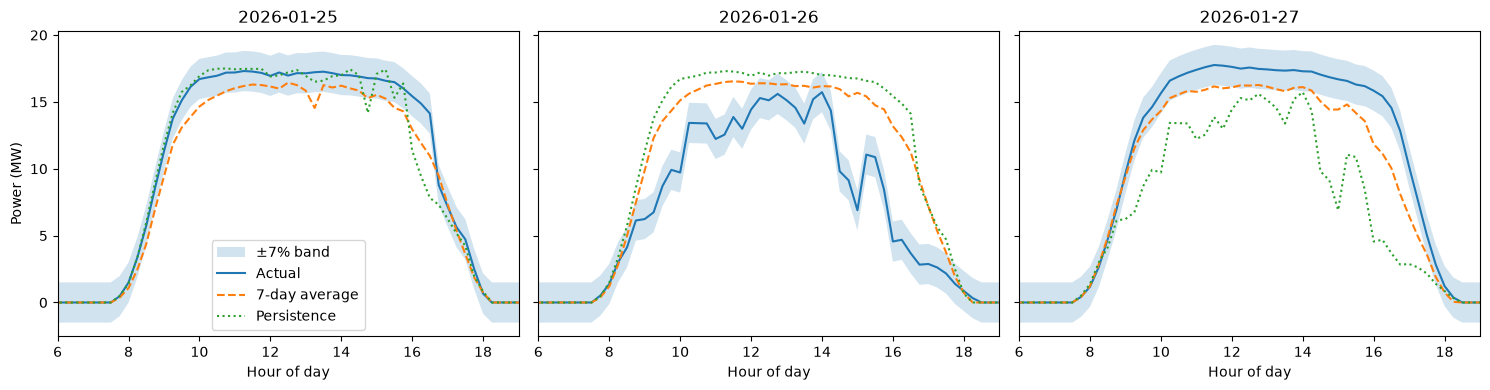

In [9]:
# Same three days as the persistence notebook: clear, cloudy, clear.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, day in zip(axes, ["2026-01-25", "2026-01-26", "2026-01-27"]):
    d = df[df["Date"] == day]
    hours = (d["Block"] - 1) / 4
    ax.fill_between(hours, d["actual"] - BAND_MW, d["actual"] + BAND_MW, alpha=0.2, label="±7% band")
    ax.plot(hours, d["actual"], label="Actual")
    ax.plot(hours, d["forecast"], "--", label="7-day average")
    ax.plot(hours, d["persistence"], ":", label="Persistence")
    ax.set_title(day)
    ax.set_xlabel("Hour of day")
    ax.set_xlim(6, 19)
axes[0].set_ylabel("Power (MW)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 7. Save forecasts and scores

In [10]:
(RESULTS / "predictions").mkdir(parents=True, exist_ok=True)
(RESULTS / "metrics").mkdir(parents=True, exist_ok=True)

df[["TimeStamp", "Date", "Block", "split", "actual", "forecast"]].to_csv(RESULTS / "predictions" / "seven_day_average.csv", index=False)
metrics.to_csv(RESULTS / "metrics" / "seven_day_average.csv", index=False)